# Predicción del precio por noche de Airbnb en Ciudad de México

**Maestría en Inteligencia Artificial · Machine Learning (Aprendizaje Supervisado)**
**Autor:** Jaime Astudillo · noviembre de 2026

## 1. Introducción

Fijar el precio por noche en Airbnb es difícil: si es alto se pierden reservas, y si es bajo, ingresos. En este proyecto estimo el **precio publicado** de alojamientos completos en Ciudad de México a partir de su capacidad, ubicación, reseñas, servicios y descripción, y comparo dos técnicas de regresión con un protocolo sin fuga de información. El resultado estima el precio de oferta, no el precio pagado.

In [1]:
# Prompt (IA, Claude): «Instala lo que falte en Colab, importa las librerías y fija la semilla»
import os, sys, subprocess, logging
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentence-transformers>=6.3', 'optuna>=5.1'], check=True)
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
logging.getLogger('torch.distributed.elastic.multiprocessing.redirects').setLevel(logging.ERROR)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, optuna, torch
from joblib import Parallel, delayed
from scipy import stats
from sentence_transformers import SentenceTransformer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectPercentile, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.manifold import TSNE
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, learning_curve, validation_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#898781'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 2. Datos y limpieza

Uso el *snapshot* de Ciudad de México del 23 de septiembre de 2026 de Inside Airbnb [1] (licencia CC BY 4.0). Aplico filtros con umbrales fijos, no calculados con los datos:

| Filtro | Motivo |
|---|---|
| Precio publicado | Es la variable objetivo |
| Alojamiento completo | Una habitación privada es otro producto |
| ≥ 1 reseña en 12 meses | El precio debe estar vigente |
| 300–30 000 MXN por noche | Quita errores de captura y casos extremos |
| Estancia mínima ≤ 30 noches | Excluye arriendos mensuales |
| Sin duplicados exactos (texto y coordenadas) | Son el mismo anuncio publicado dos veces |

Luego tomo una muestra de 5 000 anuncios, por el costo de la validación anidada.

In [2]:
# Prompt (IA, Claude): «Carga el listado de Inside Airbnb, aplica los filtros y reporta cuántos anuncios
# quedan tras cada uno; toma una muestra reproducible de 5 000»
URL = 'https://data.insideairbnb.com/mexico/df/mexico-city/2026-09-23/data/listings.csv.gz'
raw = pd.read_csv('data/listings.csv.gz' if os.path.exists('data/listings.csv.gz') else URL, low_memory=False)
raw['price'] = pd.to_numeric(raw['price'].astype(str).str.replace(r'[$,]', '', regex=True), errors='coerce')
print('Columnas vacías en el snapshot:', sum(raw[c].isna().all() for c in raw), '(p. ej. host_since, instant_bookable)')

filters = {'Con precio publicado': lambda d: d['price'] > 0,
           'Alojamiento completo': lambda d: d['room_type'] == 'Entire home/apt',
           'Activo (≥ 1 reseña en 12 meses)': lambda d: d['number_of_reviews_ltm'] >= 1,
           'Precio 300–30 000 MXN': lambda d: d['price'].between(300, 30_000),
           'Estancia mínima ≤ 30 noches': lambda d: d['minimum_nights'] <= 30,
           'Sin duplicados': lambda d: ~d.duplicated(['description', 'latitude', 'longitude'])}
df, steps = raw, {'Snapshot': len(raw)}
for label, rule in filters.items():
    df = df[rule(df)]
    steps[label] = len(df)
df = df.sample(n=5_000, random_state=SEED).reset_index(drop=True)
steps['Muestra'] = len(df)
pd.Series(steps, name='anuncios').to_frame()

Columnas vacías en el snapshot: 15 (p. ej. host_since, instant_bookable)


,anuncios
Snapshot,30468
Con precio publicado,28360
Alojamiento completo,18975
Activo (≥ 1 reseña en 12 meses),15972
Precio 300–30 000 MXN,15955
Estancia mínima ≤ 30 noches,15948
Sin duplicados,15412
Muestra,5000


**Variables.** Son 14 numéricas (capacidad, dormitorios, camas, baños, latitud, longitud, distancia al Zócalo, estancia mínima, reseñas, calificación general y de ubicación, disponibilidad, número de servicios y superhost), 2 categóricas (alcaldía y tipo de propiedad) y la descripción. Las construyo con reglas fijas por fila, así que no hay fuga. Excluyo el id, la URL, los datos del anfitrión y las variables derivadas del precio.

In [3]:
# Prompt (IA, Claude): «Construye las variables: baños desde el texto, número de servicios, superhost,
# distancia al Zócalo y descripción sin HTML»
baths = df['bathrooms_text'].str.extract(r'([\d.]+)')[0].astype(float)
df['baths'] = baths.fillna(df['bathrooms_text'].str.contains('half', case=False, na=False).map({True: 0.5, False: np.nan}))
df['n_amenities'] = df['amenities'].str.count('",') + df['amenities'].str.contains('"').astype(int)
df['superhost'] = df['host_is_superhost'].map({'t': 1, 'f': 0})
lat, lon, zlat, zlon = map(np.radians, (df['latitude'], df['longitude'], 19.4326, -99.1332))  # Zócalo
df['dist_centro_km'] = 2 * 6371 * np.arcsin(np.sqrt(np.sin((lat - zlat) / 2) ** 2
                                                    + np.cos(lat) * np.cos(zlat) * np.sin((lon - zlon) / 2) ** 2))
df['description_clean'] = df['description'].fillna('').str.replace(r'<[^>]+>', ' ', regex=True).str.strip()

NUM = ['accommodates', 'bedrooms', 'beds', 'baths', 'latitude', 'longitude', 'dist_centro_km', 'minimum_nights',
       'number_of_reviews', 'review_scores_rating', 'review_scores_location', 'availability_365', 'n_amenities',
       'superhost']
CAT = ['neighbourhood_cleansed', 'property_type']

## 3. Partición

Separo el 20 % para prueba antes de explorar o ajustar nada. Un anfitrión suele publicar varias unidades casi iguales; si unas quedaran en train y otras en prueba, el modelo vería casi la respuesta. Por eso la partición y todas las validaciones cruzadas se **agrupan por anfitrión** (`StratifiedGroupKFold`, estratificado por quintil de precio): cada anfitrión queda entero en un solo lado. Su id solo se usa para agrupar, no como variable.

In [4]:
# Prompt (IA, Claude): «Define folds repetidos agrupados por anfitrión y estratificados por quintil de precio;
# separa train/test 80/20 con ellos y verifica que no compartan anfitriones ni descripciones»
def group_folds(y, groups, k, r):
    q = pd.qcut(y, 5, labels=False)
    return [f for i in range(r) for f in StratifiedGroupKFold(k, shuffle=True, random_state=SEED + i).split(y, q, groups)]


tr, te = group_folds(df['price'], df['host_id'], 5, 1)[0]
desc_tr, desc_te = df['description_clean'].iloc[tr], df['description_clean'].iloc[te]
shared = desc_te[desc_te.isin(desc_tr[desc_tr != ''])]
print(f"Train: {len(tr)} | test: {len(te)} | anfitriones en ambos: {len(set(df['host_id'].iloc[tr]) & set(df['host_id'].iloc[te]))}")
print(f'Descripciones de test repetidas en train: {len(shared)}; la más común: «{shared.value_counts().index[0]}»')

Train: 4000 | test: 1000 | anfitriones en ambos: 0
Descripciones de test repetidas en train: 25; la más común: «Enjoy the simplicity of this quiet and central accommodation.»


Ningún anfitrión queda en ambos lados. Las 25 descripciones de prueba que coinciden con alguna de train son de anfitriones distintos y son frases genéricas como la que se imprime. Eso no garantiza que sean viviendas distintas, pero controla la fuente principal de unidades clonadas: el mismo anfitrión.

## 4. Análisis exploratorio (solo train)

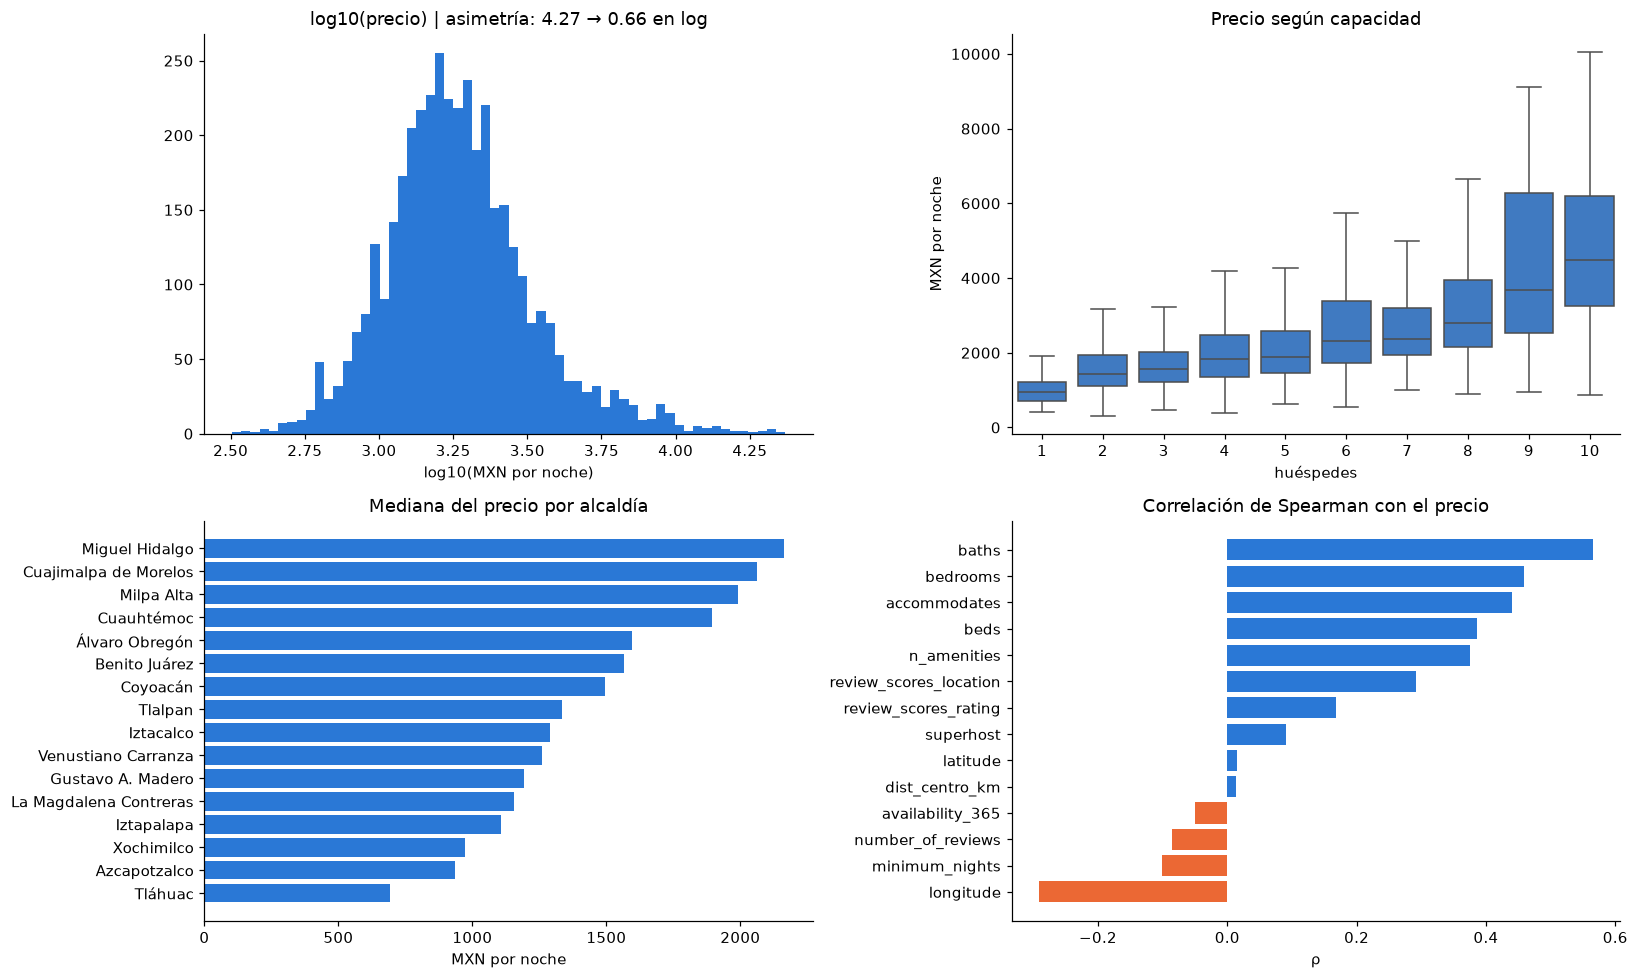

Precio: mediana 1,777 | media 2,247 MXN
Faltantes (%): {'beds': 1.1} | anuncios por alcaldía (mín.): 3


In [5]:
# Prompt (IA, Claude): «EDA solo con train en una figura: distribución del precio, precio por capacidad y por
# alcaldía, y correlación de Spearman con el precio; resume faltantes»
eda = df.iloc[tr]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
ax[0, 0].hist(np.log10(eda['price']), bins=60, color=BLUE)
ax[0, 0].set(title=f"log10(precio) | asimetría: {eda['price'].skew():.2f} → {np.log10(eda['price']).skew():.2f} en log",
             xlabel='log10(MXN por noche)')
sns.boxplot(data=eda[eda['accommodates'] <= 10], x='accommodates', y='price', color=BLUE, showfliers=False, ax=ax[0, 1])
ax[0, 1].set(title='Precio según capacidad', xlabel='huéspedes', ylabel='MXN por noche')
by_area = eda.groupby('neighbourhood_cleansed')['price'].median().sort_values()
ax[1, 0].barh(by_area.index, by_area, color=BLUE)
ax[1, 0].set(title='Mediana del precio por alcaldía', xlabel='MXN por noche')
rho = eda[NUM].corrwith(eda['price'], method='spearman').sort_values()
ax[1, 1].barh(rho.index, rho, color=[ORANGE if v < 0 else BLUE for v in rho])
ax[1, 1].set(title='Correlación de Spearman con el precio', xlabel='ρ')
plt.tight_layout()
plt.show()
print(f"Precio: mediana {eda['price'].median():,.0f} | media {eda['price'].mean():,.0f} MXN")
print('Faltantes (%):', eda[NUM + CAT].isna().mean().mul(100).round(1).loc[lambda s: s > 0].to_dict(),
      '| anuncios por alcaldía (mín.):', eda['neighbourhood_cleansed'].value_counts().min())

- **Precio muy asimétrico** (asimetría de 4.27, que baja a 0.66 en log; mediana de 1 777 MXN y media de 2 247 MXN): por eso entreno con log(precio).
- **El tamaño es lo más asociado al precio:** baños, dormitorios y capacidad tienen las mayores correlaciones de Spearman.
- **La ubicación importa, pero no como distancia al centro** (ρ ≈ 0): son caros el poniente (Miguel Hidalgo, Cuajimalpa) y el centro (Cuauhtémoc), y baratos Tláhuac, Azcapotzalco y Xochimilco; por eso la longitud tiene correlación negativa. Conservo la alcaldía y las coordenadas.
- **Calidad de los datos:** solo `beds` tiene faltantes (1.1 %), que se imputan en el pipeline. Algunas alcaldías tienen muy pocos anuncios (mínimo 3), así que su mediana es poco fiable, y el *one-hot* las agrupa.

## 5. Extracción de características (*transfer learning*)

Convierto la descripción en un vector con `paraphrase-multilingual-MiniLM-L12-v2` [2], [3], un modelo preentrenado y congelado. Tokeniza el texto en subpalabras, lo pasa por 12 capas *transformer* y promedia los tokens (*mean pooling*) para obtener un vector de 384 dimensiones; lee como máximo 128 tokens. Como no aprende de mis datos, aplicarlo a todos los anuncios no filtra información. El PCA de esos vectores va dentro del pipeline.

In [6]:
# Prompt (IA, Claude): «Convierte las descripciones en embeddings con un modelo multilingüe de
# sentence-transformers y agrégalos como columnas»
encoder = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2', device='cuda' if torch.cuda.is_available() else 'cpu')
emb = encoder.encode(df['description_clean'].tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
EMB = [f'emb_{i}' for i in range(emb.shape[1])]
df = pd.concat([df, pd.DataFrame(emb, columns=EMB)], axis=1)
tokens = np.array([len(t) for t in encoder.tokenizer(df['description_clean'].tolist(), verbose=False)['input_ids']])
print(f'{emb.shape[1]} dimensiones | pooling: {encoder[1].pooling_mode} | máx. {encoder.max_seq_length} tokens | '
      f'truncadas: {np.mean(tokens > encoder.max_seq_length):.1%}')

384 dimensiones | pooling: mean | máx. 128 tokens | truncadas: 4.6%


## 6. Pipeline

El pipeline [4] hace:

1. **Preprocesamiento:** las numéricas se imputan con la mediana y se escalan; las categóricas, con la moda y *one-hot*; el texto pasa por un PCA a 20 componentes.
2. **Selección filter:** `SelectPercentile(f_regression)`; el percentil es un hiperparámetro.
3. **Modelo:** todo va dentro de `TransformedTargetRegressor`, que entrena con log(1 + precio) y devuelve las predicciones en MXN.

In [7]:
# Prompt (IA, Claude): «Arma X/y de train y test con la partición anterior y define el pipeline: preprocesamiento por
# tipo de columna, PCA del texto, SelectPercentile con f_regression y el modelo, con el precio en escala log»
X, y = df[NUM + CAT + EMB], df['price']
X_train, X_test, y_train, y_test, g_train = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], df['host_id'].iloc[tr]


def build(model, percentile=100):
    pre = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False)), CAT),
        ('txt', make_pipeline(StandardScaler(), PCA(n_components=20, random_state=SEED)), EMB)])
    pipe = Pipeline([('pre', pre), ('select', SelectPercentile(f_regression, percentile=percentile)), ('model', model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

## 7. Optimización de hiperparámetros

Comparo **Ridge** [5] (lineal, con regularización L2 de parámetro λ = `alpha`) y **Random Forest** [6] (no lineal). Optimizo sus hiperparámetros con **Optuna** [7] (TPE, 30 pruebas por modelo), minimizando el MAE con validación cruzada agrupada por anfitrión de 2 repeticiones con 5 folds, solo sobre train; es la opción reducida que permite la guía cuando el costo es alto.

In [8]:
# Prompt (IA, Claude): «Define el espacio de búsqueda de cada modelo (incluido el percentil de la selección) y una
# función que lo optimice con Optuna minimizando el MAE con CV repetida 2x5 agrupada; optimiza ambos sobre train»
SPACES = {
    'Ridge': lambda t: build(Ridge(alpha=t.suggest_float('alpha', 1e-3, 1e5, log=True)),
                             t.suggest_int('percentile', 10, 100, step=10)),
    'Random Forest': lambda t: build(RandomForestRegressor(
        n_estimators=t.suggest_int('n_estimators', 100, 300, step=50), max_depth=t.suggest_int('max_depth', 4, 30),
        min_samples_leaf=t.suggest_int('min_samples_leaf', 1, 20), max_features=t.suggest_float('max_features', 0.2, 1.0),
        random_state=SEED, n_jobs=1), t.suggest_int('percentile', 10, 100, step=10))}


def tune(name, X, y, groups, n_jobs=-1):
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    cv = group_folds(y, groups, 5, 2)
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(lambda t: -cross_val_score(SPACES[name](t), X, y, cv=cv, scoring='neg_mean_absolute_error',
                                              n_jobs=n_jobs).mean(), n_trials=30)
    return study


studies = {name: tune(name, X_train, y_train, g_train) for name in SPACES}
best = {name: SPACES[name](optuna.trial.FixedTrial(s.best_params)) for name, s in studies.items()}
for name, s in studies.items():
    print(f'{name}: MAE CV = {s.best_value:,.1f} MXN | {s.best_params}')

Ridge: MAE CV = 700.4 MXN | {'alpha': 717.7141927992017, 'percentile': 60}
Random Forest: MAE CV = 639.4 MXN | {'n_estimators': 200, 'max_depth': 21, 'min_samples_leaf': 5, 'max_features': 0.6177756702267028, 'percentile': 80}


Ridge: MAE train 687 | validación 749 → 700 MXN


Random Forest: MAE train 396 | validación 711 → 640 MXN


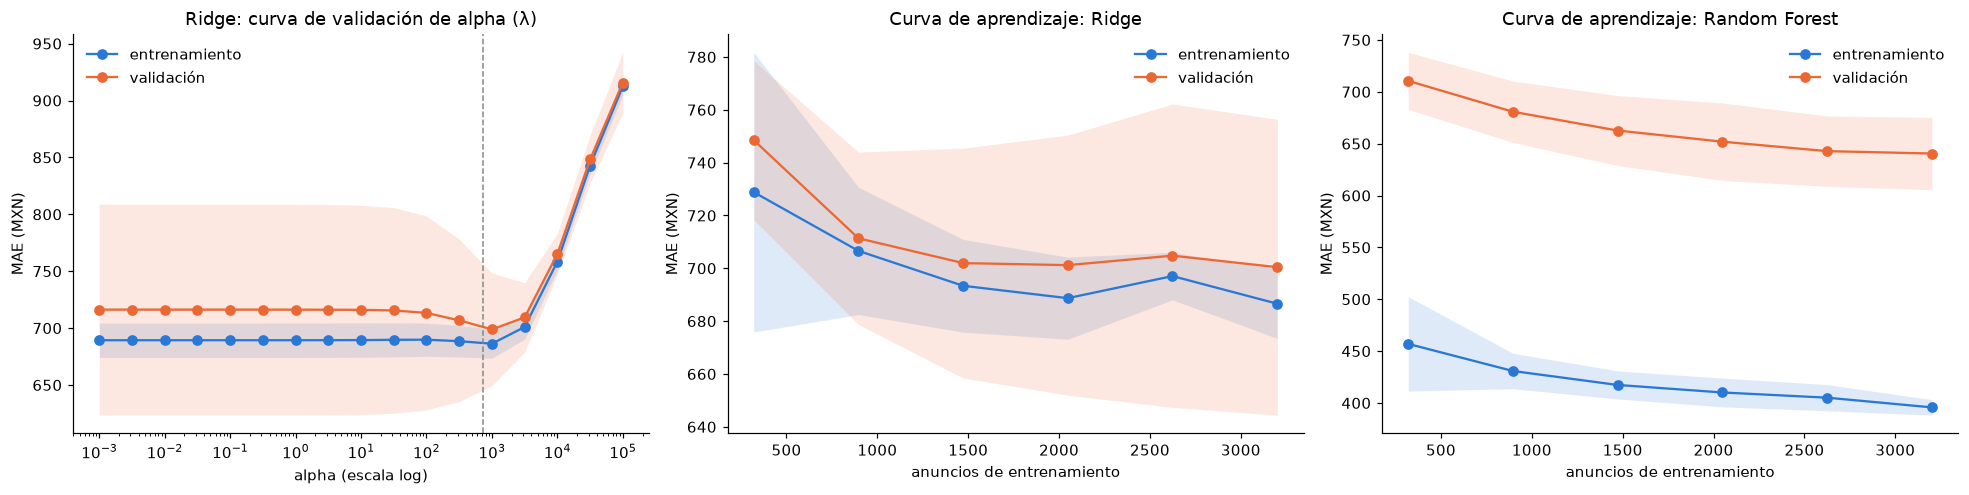

In [9]:
# Prompt (IA, Claude): «Grafica la curva de validación de alpha (Ridge) y las curvas de aprendizaje de ambos
# modelos, con entrenamiento y validación»
def plot(ax, x, tr, va, title, xlabel, log=False):
    for s, color, label in [(-tr, BLUE, 'entrenamiento'), (-va, ORANGE, 'validación')]:
        ax.plot(x, s.mean(1), 'o-', color=color, label=label)
        ax.fill_between(x, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=color, alpha=0.15, lw=0)
    ax.set(title=title, xlabel=xlabel, ylabel='MAE (MXN)', xscale='log' if log else 'linear')
    ax.legend(frameon=False)


cv_opt, p_ridge, alphas = group_folds(y_train, g_train, 5, 2), studies['Ridge'].best_params, np.logspace(-3, 5, 17)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
plot(ax[0], alphas, *validation_curve(build(Ridge(), p_ridge['percentile']), X_train, y_train,
                                      param_name='regressor__model__alpha', param_range=alphas, cv=cv_opt,
                                      scoring='neg_mean_absolute_error', n_jobs=-1),
     'Ridge: curva de validación de alpha (λ)', 'alpha (escala log)', log=True)
ax[0].axvline(p_ridge['alpha'], color=GRAY, ls='--', lw=1)
for a, name in zip(ax[1:], best):
    n, tr_s, va_s = learning_curve(best[name], X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 6), cv=cv_opt,
                                   scoring='neg_mean_absolute_error', n_jobs=-1, shuffle=True, random_state=SEED)
    plot(a, n, tr_s, va_s, f'Curva de aprendizaje: {name}', 'anuncios de entrenamiento')
    print(f'{name}: MAE train {-tr_s.mean(1)[-1]:,.0f} | validación {-va_s.mean(1)[0]:,.0f} → {-va_s.mean(1)[-1]:,.0f} MXN')
plt.tight_layout()
plt.show()

- **Ridge** (mejor λ = 718): train y validación quedan cerca (687 frente a 700 MXN en el mayor tamaño de la curva, unos 3 200 anuncios por fold), así que no sobreajusta. Con λ ≥ 10⁴ ambas curvas suben (subajuste). Su curva de aprendizaje se aplana pronto: tiene **sesgo alto**, y los rendimientos decrecientes sugieren que más datos lo ayudarían poco.
- **Random Forest:** tiene **varianza alta**, con una brecha grande entre train y validación (396 frente a 640 MXN), pero la validación sigue bajando con más datos (de 711 a 640 MXN). Usar los 15 412 anuncios en vez de 5 000 probablemente lo mejoraría.

## 8. Comparación estadística

Si evaluara los modelos con los mismos datos con que elegí sus hiperparámetros, el MAE saldría optimista. Por eso uso **validación cruzada anidada** [8]: una CV externa agrupada por anfitrión de 2 repeticiones con 10 folds (10×2 en la figura) y, dentro de cada fold externo, la misma búsqueda de Optuna de la sección 7 con solo el train de ese fold. Así cada MAE externo evalúa el procedimiento completo (optimizar y entrenar) con datos que no intervinieron en la búsqueda. Ambos modelos usan los mismos folds (resultados emparejados). Uso 2 repeticiones y no 10 porque cada fold externo repite toda la búsqueda: son 40 búsquedas en total.

- **Hipótesis:** H₀ dice que el MAE esperado es igual; H₁, que es distinto (α = 0.05).
- **Prueba principal:** como los folds comparten datos, no son independientes, así que uso la **prueba t corregida de Nadeau-Bengio** [9], [10], que infla la varianza por (1/n + n_test/n_train).
- **Contraste:** reporto también **Wilcoxon** [11], que no corrige esa dependencia.

                     mean   std
Baseline (mediana)  982.3  54.6
Ridge               703.8  82.4
Random Forest       639.0  39.2

Ridge − RF: 64.7 MXN (RF gana en 20/20 folds) | t corregida = 2.30, p = 0.0327 | Wilcoxon p = 1.9e-06


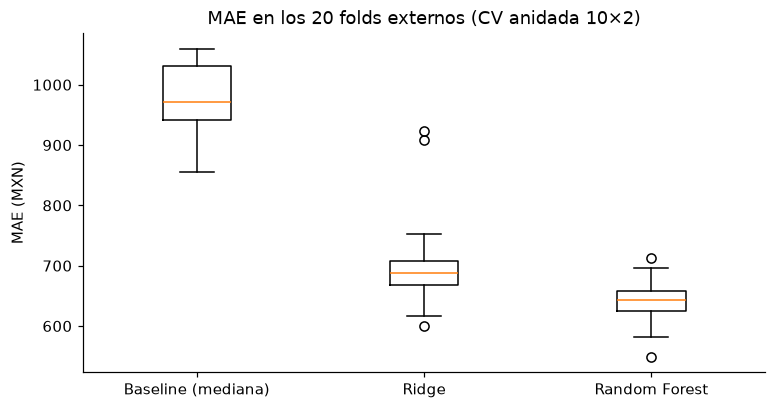

In [10]:
# Prompt (IA, Claude): «Compara Ridge y Random Forest con CV anidada: CV externa 10x2 agrupada y, en cada fold
# externo, la misma búsqueda de Optuna solo con su train; paraleliza los folds, aplica la t corregida de
# Nadeau-Bengio y Wilcoxon, e incluye el baseline»
outer = group_folds(y_train, g_train, 10, 2)


def nested_mae(name, a, b):
    model = SPACES[name](optuna.trial.FixedTrial(
        tune(name, X_train.iloc[a], y_train.iloc[a], g_train.iloc[a], n_jobs=1).best_params))
    model.fit(X_train.iloc[a], y_train.iloc[a])
    return mean_absolute_error(y_train.iloc[b], model.predict(X_train.iloc[b]))


res = Parallel(n_jobs=-1)(delayed(nested_mae)(name, a, b) for name in SPACES for a, b in outer)
mae = {'Baseline (mediana)': -cross_val_score(DummyRegressor(strategy='median'), X_train, y_train, cv=outer,
                                              scoring='neg_mean_absolute_error')}
mae |= dict(zip(SPACES, np.reshape(res, (len(SPACES), -1))))

d = mae['Ridge'] - mae['Random Forest']
ratio = np.mean([len(b) / len(a) for a, b in outer])  # n_test/n_train ≈ 1/9 con 10 folds
t = d.mean() / np.sqrt((1 / len(d) + ratio) * d.var(ddof=1))
p = 2 * stats.t.sf(abs(t), df=len(d) - 1)
print(pd.DataFrame(mae).agg(['mean', 'std']).T.round(1).to_string())
print(f'\nRidge − RF: {d.mean():.1f} MXN (RF gana en {(d > 0).sum()}/{len(d)} folds) | t corregida = {t:.2f}, '
      f'p = {p:.4f} | Wilcoxon p = {stats.wilcoxon(mae["Ridge"], mae["Random Forest"]).pvalue:.1e}')
plt.figure(figsize=(8, 4))
plt.boxplot(list(mae.values()), tick_labels=list(mae))
plt.ylabel('MAE (MXN)')
plt.title(f'MAE en los {len(outer)} folds externos (CV anidada 10×2)')
plt.show()

Random Forest tiene un MAE medio de 639 MXN frente a 704 MXN de Ridge y gana en los 20 folds externos; además es más estable (desviación de 39 frente a 82 MXN). Con la t corregida, t = 2.30 y p = 0.033 < 0.05, así que **rechazo H₀**: Random Forest es mejor en este problema. Wilcoxon coincide (p = 1.9 × 10⁻⁶, el mínimo posible con 20 pares), pero no corrige la dependencia entre folds. El p-valor no implica causalidad; la explicación probable es que Random Forest capta interacciones, como que un baño extra no valga lo mismo en todas las zonas.

## 9. Evaluación final en prueba

Elijo el modelo con menor MAE en la validación anidada, lo reentreno con todo train y los hiperparámetros de la sección 7, y lo evalúo **una sola vez** en prueba. El MAE es el error típico en MXN, el RMSE penaliza los errores grandes y R² es la fracción de la varianza del precio que explica el modelo.

In [11]:
# Prompt (IA, Claude): «Elige el modelo con menor MAE en la CV anidada, reentrénalo con todo train y evalúalo una vez
# en test (MAE, RMSE, R² en MXN) junto al baseline»
chosen = min(SPACES, key=lambda name: mae[name].mean())
final = best[chosen].fit(X_train, y_train)
pred = final.predict(X_test)
metrics = lambda yhat: {'MAE': mean_absolute_error(y_test, yhat), 'RMSE': np.sqrt(mean_squared_error(y_test, yhat)),
                        'R²': r2_score(y_test, yhat)}
pd.DataFrame({chosen: metrics(pred),
              'Baseline': metrics(DummyRegressor(strategy='median').fit(X_train, y_train).predict(X_test))}).T.round(3)

,MAE,RMSE,R²
Random Forest,740.298,1783.860,0.371
Baseline,1065.503,2319.506,-0.063


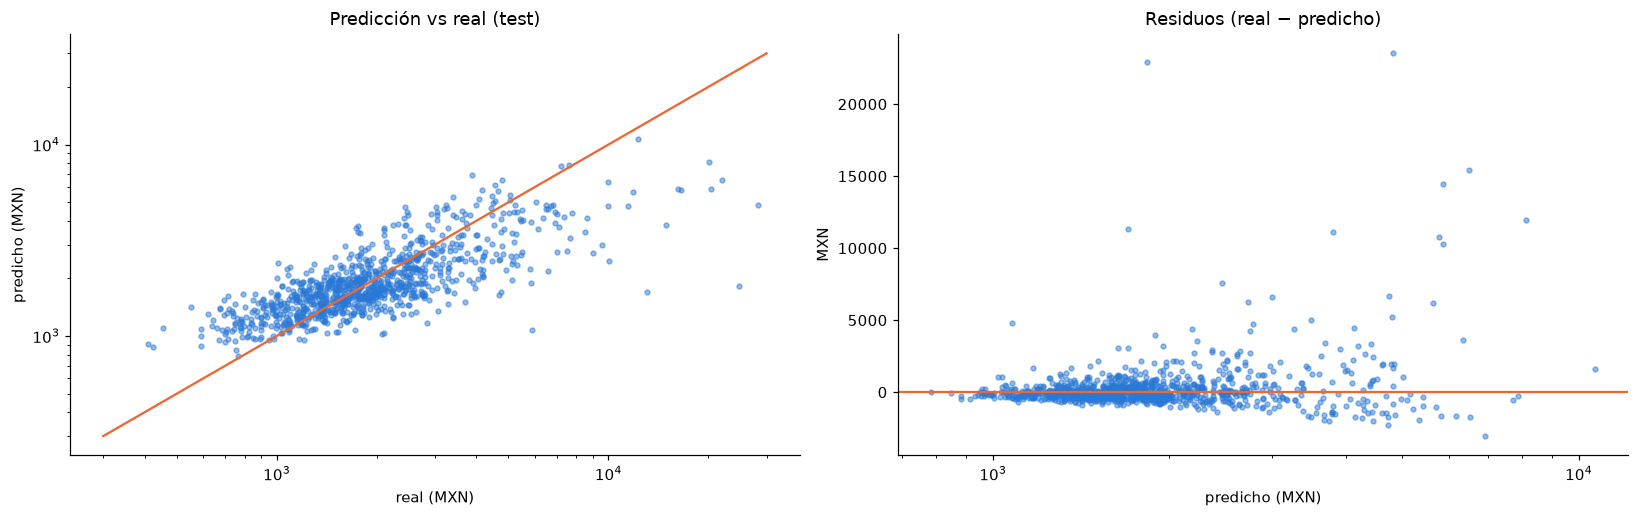

price  Q1 barato     Q2     Q3     Q4  Q5 caro
MAE        384.0  272.0  328.0  525.0   2193.0
sesgo      380.0  197.0   54.0 -212.0  -1845.0



SelectPercentile conservó 43 de 54 variables


,aumento del MAE (MXN)
baths,223.4
longitude,52.2
bedrooms,35.9
n_amenities,30.7
latitude,24.4
descripción (embedding),17.2
review_scores_rating,12.0
accommodates,10.7


In [12]:
# Prompt (IA, Claude): «Grafica predicción vs real y residuos, resume el error por quintil de precio y calcula la
# importancia por permutación agrupada (cada variable original y el embedding completo como un bloque)»
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].scatter(y_test, pred, s=10, alpha=0.5, color=BLUE)
ax[0].plot([300, 30_000], [300, 30_000], color=ORANGE)
ax[0].set(xscale='log', yscale='log', title='Predicción vs real (test)', xlabel='real (MXN)', ylabel='predicho (MXN)')
ax[1].scatter(pred, y_test - pred, s=10, alpha=0.5, color=BLUE)
ax[1].axhline(0, color=ORANGE)
ax[1].set(xscale='log', title='Residuos (real − predicho)', xlabel='predicho (MXN)', ylabel='MXN')
plt.tight_layout()
plt.show()

q = pd.qcut(y_test, 5, labels=['Q1 barato', 'Q2', 'Q3', 'Q4', 'Q5 caro'])
print(pd.DataFrame({'MAE': (y_test - pred).abs(), 'sesgo': pred - y_test}).groupby(q, observed=True).mean().round(0).T.to_string())

rng, base = np.random.default_rng(SEED), mean_absolute_error(y_test, pred)
blocks = {c: [c] for c in NUM + CAT} | {'descripción (embedding)': EMB}
imp = {}
for name, cols in blocks.items():
    deltas = []
    for _ in range(5):
        Xp = X_test.copy()
        Xp[cols] = X_test[cols].to_numpy()[rng.permutation(len(X_test))]
        deltas.append(mean_absolute_error(y_test, final.predict(Xp)) - base)
    imp[name] = np.mean(deltas)
kept = final.regressor_['select'].get_support().sum()
print(f'\nSelectPercentile conservó {kept} de {len(final.regressor_["select"].get_support())} variables')
pd.Series(imp, name='aumento del MAE (MXN)').sort_values(ascending=False).round(1).head(8).to_frame()

- **En prueba**, Random Forest logra un MAE de 740 MXN, un RMSE de 1 784 MXN y un R² de 0.37: un 31 % menos de error que el baseline (1 066 MXN). Es peor que en la CV anidada (639 MXN), pero el baseline también empeora (1 066 frente a 982 MXN): esta partición de prueba es más difícil que el promedio, y la diferencia se concentra en los anuncios caros.
- **Comprime los extremos:** sobreestima los baratos (+380 MXN en Q1) y subestima mucho los caros (−1 845 MXN en Q5, con un MAE de 2 193 MXN). El lujo depende de atributos que no están en los datos, como la vista o el diseño.
- **La variable más importante son los baños** (+223 MXN de MAE al permutarlos); les siguen longitud, dormitorios, servicios, latitud y la descripción (+17 MXN). Importancia no implica causalidad.

## 10. t-SNE de lo que ve el modelo

Proyecto con t-SNE [12] la salida del pipeline final **justo antes del modelo**, es decir, después del preprocesamiento y la selección, y coloreo los anuncios de train por quintil de precio.

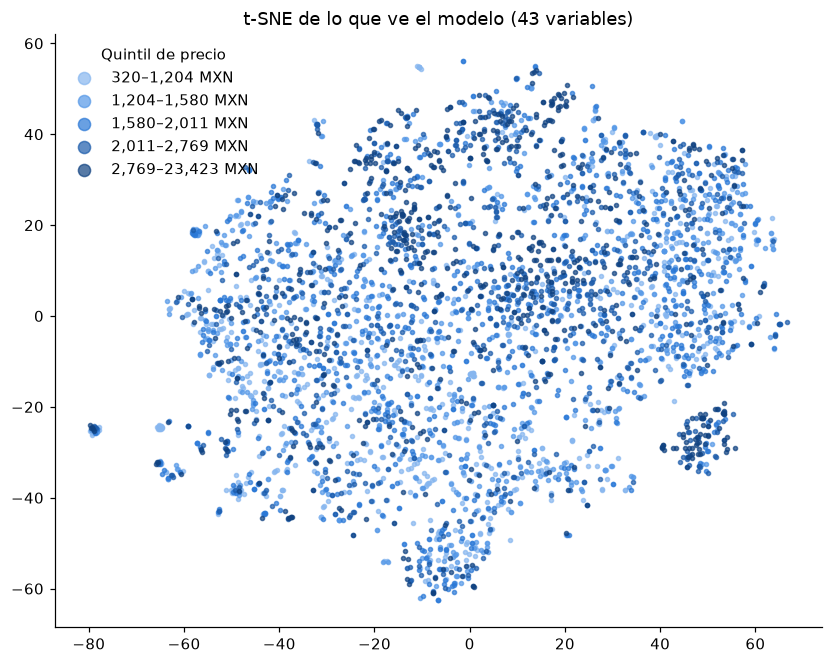

In [13]:
# Prompt (IA, Claude): «Proyecta con t-SNE lo que ve el modelo final (el pipeline sin su último paso) y colorea por
# quintil de precio»
Z = final.regressor_[:-1].transform(X_train)
Z2 = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(Z)
q = pd.qcut(y_train, 5)
plt.figure(figsize=(9, 7))
for i, (iv, color) in enumerate(zip(q.cat.categories, ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281'])):
    m = (q.cat.codes == i).to_numpy()
    plt.scatter(Z2[m, 0], Z2[m, 1], s=7, alpha=0.7, color=color, label=f'{iv.left:,.0f}–{iv.right:,.0f} MXN')
plt.title(f't-SNE de lo que ve el modelo ({Z.shape[1]} variables)')
plt.legend(title='Quintil de precio', markerscale=3, frameon=False)
plt.show()

Los quintiles se mezclan: no hay grupos separados por precio, solo tendencias locales y algunos grupos pequeños de anuncios con variables casi idénticas. Es coherente con un R² de 0.37. t-SNE solo conserva vecindades locales, así que es una visualización exploratoria, no una prueba de capacidad predictiva.

## 11. Conclusiones

1. El precio por noche de un alojamiento completo se puede estimar con un error típico de 740 MXN en prueba (R² = 0.37), un 31 % menos que con la mediana. Sirve como referencia, pero subestima los alojamientos de lujo.
2. Random Forest es significativamente mejor que Ridge en la validación anidada (639 frente a 704 MXN; p = 0.033 con la t corregida).
3. Ridge falla por sesgo y Random Forest por varianza; lo siguiente con más retorno probablemente es entrenar Random Forest con todos los anuncios.
4. El tamaño (los baños) y la ubicación dominan la predicción; la descripción aporta menos (+17 MXN).

**Limitaciones:**
- Es un precio publicado en una sola fecha (sin estacionalidad).
- Solo incluye alojamientos completos activos.
- Las coordenadas están desplazadas hasta unos 150 m por privacidad.
- La prueba es una sola partición de 1 000 anuncios: pocos anuncios de lujo mueven mucho su MAE.
- El modelo solo vale para Ciudad de México.

## Uso de IA

El código se generó con Claude (Anthropic) [13]; cada celda indica su prompt como comentario, según la guía del curso. Revisé y ejecuté todo el código.

## Referencias

[1] Inside Airbnb, «Get the Data: Mexico City (23 September 2026)», 2026. [En línea]. Disponible: https://insideairbnb.com/get-the-data/

[2] N. Reimers e I. Gurevych, «Sentence-BERT: Sentence embeddings using Siamese BERT-networks», en *Proc. EMNLP-IJCNLP*, 2019, pp. 3982–3992.

[3] N. Reimers e I. Gurevych, «Making monolingual sentence embeddings multilingual using knowledge distillation», en *Proc. EMNLP*, 2020, pp. 4512–4525.

[4] F. Pedregosa *et al.*, «Scikit-learn: Machine learning in Python», *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[5] A. E. Hoerl y R. W. Kennard, «Ridge regression: Biased estimation for nonorthogonal problems», *Technometrics*, vol. 12, n.º 1, pp. 55–67, 1970.

[6] L. Breiman, «Random forests», *Mach. Learn.*, vol. 45, n.º 1, pp. 5–32, 2001.

[7] T. Akiba, S. Sano, T. Yanase, T. Ohta y M. Koyama, «Optuna: A next-generation hyperparameter optimization framework», en *Proc. ACM SIGKDD*, 2019, pp. 2623–2631.

[8] G. C. Cawley y N. L. C. Talbot, «On over-fitting in model selection and subsequent selection bias in performance evaluation», *J. Mach. Learn. Res.*, vol. 11, pp. 2079–2107, 2010.

[9] C. Nadeau e Y. Bengio, «Inference for the generalization error», *Mach. Learn.*, vol. 52, n.º 3, pp. 239–281, 2003.

[10] R. R. Bouckaert y E. Frank, «Evaluating the replicability of significance tests for comparing learning algorithms», en *Proc. PAKDD*, LNCS 3056, 2004, pp. 3–12.

[11] F. Wilcoxon, «Individual comparisons by ranking methods», *Biometrics Bull.*, vol. 1, n.º 6, pp. 80–83, 1945.

[12] L. van der Maaten y G. Hinton, «Visualizing data using t-SNE», *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.

[13] Anthropic, «Claude», 2026. [En línea]. Disponible: https://www.anthropic.com/claude